# Reranker-Only Pipeline: Logged MIND Slates -> Rule Baselines and RR4 Reranker -> Final K

This notebook evaluates the **reranking stage on its own**. It does not require any other
notebook to be executed first.

1. **Candidates**: the exact slates MIND logged. Every impression keeps the articles that were
   actually shown, so no candidate generator is involved and every candidate has a click label.
2. **Rule baselines**: causal popularity (smoothed prior article CTR) and content similarity
   (entity cosine to the user's causal click profile). Neither has trainable parameters.
3. **Reranker**: trains the `RR_4` `+metadata` attention reranker inside this notebook (or loads
   its checkpoint) with the same data, preprocessing, loss and training loop as stage 3 of
   `RR_4_branch_interaction.ipynb`.
4. **Evaluation**: every model reorders the target-split slates; the ranked lists are evaluated
   at each cutoff in `K_VALUES`, overall and by user history.

Saved artifacts are the reranker checkpoint and preprocessor, one score file per model, and the
metric tables.

**Labels are complete here.** Unlike the end-to-end pipelines in `2_CG_RR_E2E`, every candidate
was shown, so a non-clicked candidate is a real negative. These metrics measure how well each
model orders a slate. They are an upper bound on reranking quality, not an estimate of the full
system, where the reranker also sees generated articles that were never shown.

## 0. Configure

**This is the only cell you need to edit.** The defaults run the full experiment on the whole
dataset. After editing, run the whole notebook with **Runtime > Run all**.

In [8]:
# ---- Where to run ----------------------------------------------------------------------------
# "colab" = Google Colab with Google Drive, "local" = this computer, "auto" = detect automatically.
RUN_ENV = "local"

# ---- Paths -------------------------------------------------------------------------------------
# Project folder: the shared folder holding the code (this repository).
# On Colab, add a shortcut to the shared folder in My Drive first; it may also sit one folder down.
COLAB_PROJECT_PATH = "/content/drive/MyDrive/BT4222-Group-6-"
LOCAL_PROJECT_PATH = None  # None = the repository this notebook is opened from

# Data path: the prepared data, set separately for Colab and local runs. It must contain
# 3_Representations/artifacts/ and 4_Feature_Engineering/artifacts/prequential-all/.
# Metrics are written to <data path>/results/.
COLAB_DATA_PATH = None  # used on Colab; None = the project folder
LOCAL_DATA_PATH = "/Users/numkoos/Downloads/v3-mindsmall"  # used locally; None = the project folder

# Model path: where the trained models are saved, and loaded from on later runs.
MODEL_PATH = None  # None = <data path>/5_Models/5_03_Pipeline_Evaluation/artifacts/reranker_logged_slates

# ---- Experiment --------------------------------------------------------------------------------
# Split to evaluate: "test" for the final results, or "validation".
TARGET_SPLIT = "test"

# Training impressions for the reranker. None = the whole training set (default).
# A number, e.g. 5_000, trains on a random sample instead for a quicker run.
TRAIN_IMPRESSIONS = None

# True: load a model saved by an earlier run when its settings match this cell (faster).
# False: always retrain from scratch.
REUSE_SAVED_MODELS = True


## 1.1 Load Packages

In [9]:
import json
import os
import random
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import pyarrow.parquet as pq
import torch
import torch.nn.functional as F
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from torch import nn

## 1.2 Set Up Paths

The run mode, project folder, data path and model path all come from the **Configure** cell
(section 0). On Colab the notebook mounts Google Drive and finds the shared project folder at
`COLAB_PROJECT_PATH`, or one folder down in My Drive. The data folders are checked up front, so a
wrong `DATA_PATH` fails here with the missing folder named.

In [10]:
# Run mode and paths come from the Configure cell (section 0)
ENVIRONMENT = RUN_ENV.lower()
if ENVIRONMENT == "auto":
    ENVIRONMENT = "colab" if "google.colab" in sys.modules else "local"
if ENVIRONMENT not in {"colab", "local"}:
    raise ValueError('RUN_ENV must be "auto", "colab" or "local"')

if ENVIRONMENT == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    requested = Path(COLAB_PROJECT_PATH)
    CODE_ROOT = next(
        (
            p for p in [requested, *Path("/content/drive/MyDrive").glob(f"*/{requested.name}")]
            if (p / "run_all.py").is_file()
        ),
        None,
    )
    if CODE_ROOT is None:
        raise FileNotFoundError(
            f"Could not find the project folder at {requested}. In Google Drive, right-click the shared "
            "folder > Organise > Add shortcut > My Drive (or fix COLAB_PROJECT_PATH), then rerun."
        )
elif LOCAL_PROJECT_PATH:
    CODE_ROOT = Path(LOCAL_PROJECT_PATH).expanduser().resolve()
else:
    CODE_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_all.py").is_file())
ROOT = CODE_ROOT
DATA_PATH = COLAB_DATA_PATH if ENVIRONMENT == "colab" else LOCAL_DATA_PATH
DATA_ROOT = Path(DATA_PATH or os.environ.get("NEWSREC_DATA_ROOT") or CODE_ROOT).expanduser().resolve()

REQUIRED_DATA = ['3_Representations/artifacts', '4_Feature_Engineering/artifacts/prequential-all']
missing_data = [str(DATA_ROOT / sub) for sub in REQUIRED_DATA if not (DATA_ROOT / sub).exists()]
if missing_data:
    raise FileNotFoundError(f"{ENVIRONMENT.upper()}_DATA_PATH is missing these folders:\n" + "\n".join(missing_data))

REPRESENTATIONS = DATA_ROOT / "3_Representations" / "artifacts"
RUN = DATA_ROOT / "4_Feature_Engineering" / "artifacts" / "prequential-all"
OUTPUT_DIR = DATA_ROOT / "5_Models" / "5_03_Pipeline_Evaluation" / "artifacts"
MODEL_DIR = Path(MODEL_PATH).expanduser().resolve() if MODEL_PATH else OUTPUT_DIR / "reranker_logged_slates"
RR4_MODEL_DIR = MODEL_DIR / "reranker"
SCORE_DIR = MODEL_DIR / "scores"
RESULTS = DATA_ROOT / "results"

sys.path.insert(0, str(ROOT / "5_Models" / "5_02_Reranking"))
from rr_evaluation import RerankingEvaluator, compare_results, write_scores

for path in (OUTPUT_DIR, MODEL_DIR, RR4_MODEL_DIR, SCORE_DIR, RESULTS):
    path.mkdir(parents=True, exist_ok=True)

print("Run mode:", ENVIRONMENT)
print("Repository:", ROOT)
print("Data path:", DATA_ROOT)
print("Model path:", MODEL_DIR)

Run mode: local
Repository: /Users/numkoos/Downloads/BT4222-Group-6-
Data path: /Users/numkoos/Downloads/v3-mindsmall
Model path: /Users/numkoos/Downloads/v3-mindsmall/5_Models/5_03_Pipeline_Evaluation/artifacts/reranker_logged_slates


## 1.3 Configuration

The RR4 settings are copied from `RR_4_branch_interaction.ipynb`:

- **Architecture**: `+metadata` (tabular + text + metadata + user self-attention).
- **Preprocessor**: fitted on the fit part of a `PREPROCESSOR_IMPRESSIONS = 10_000` training
  sample, exactly as RR_4 fitted it in its section 3.5 and reused it in stage 3.
- **Final training**: every training impression (`TRAIN_IMPRESSIONS = None` in the Configure cell), slates capped at
  100 candidates, 10% holdout, `softmax+lambda_ndcg`, up to 20 epochs with patience 3 on holdout
  nDCG@10.

`REUSE_SAVED_MODELS = True` (Configure cell) loads `reranker/model.pt` when it exists and matches the
current schema, architecture and training settings; set it to `False` to retrain.

In [11]:
TRAIN_SPLIT = "train"
K_VALUES = (5, 10, 30)
K = max(K_VALUES)
SEED = 4222

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Rule baselines
POPULARITY_MODEL = "popularity_smoothed_prior_article_ctr"
CONTENT_MODEL = "content_entity_cosine"

# RR4 reranker settings (RR_4_branch_interaction.ipynb)
CONFIG = {
    "tabular": True,
    "text": True,
    "metadata": True,
    "title_encoder": False,
    "user_encoder": True,
    "position": False,
    "candidate_pooling": False,
    "short_term": False,
}
MODEL_DIM = 64
ATTENTION_HEADS = 2
ATTENTION_DROPOUT = 0.10
HIDDEN_DIMS = (256, 64)
DROPOUT = 0.20
NDCG_K = 10
LOSS_NAME = "softmax+lambda_ndcg"
HISTORY_CAP = 30
SHORT_TERM_CAP = 10
MAX_CANDIDATES = 100
HOLDOUT_FRACTION = 0.10
PREPROCESSOR_IMPRESSIONS = 10_000   # RR_4 TRAIN_IMPRESSIONS: sample the preprocessor is fitted on
FULL_TRAIN_IMPRESSIONS = TRAIN_IMPRESSIONS  # set in the Configure cell; None = every training impression
EPOCHS = 20
PATIENCE = 3
BATCH_IMPRESSIONS = 64
SCORING_BATCH_ROWS = 2048
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
RR4_REUSE_CHECKPOINT = REUSE_SAVED_MODELS
RR4_CHECKPOINT_PATH = RR4_MODEL_DIR / "model.pt"
PREPROCESSOR_PATH = RR4_MODEL_DIR / "preprocessor.joblib"
RR4_MODEL = "attention_reranker"

TRAINING_SETTINGS = {
    "loss": LOSS_NAME,
    "max_candidates": MAX_CANDIDATES,
    "holdout_fraction": HOLDOUT_FRACTION,
    "preprocessor_impressions": PREPROCESSOR_IMPRESSIONS,
    "full_train_impressions": FULL_TRAIN_IMPRESSIONS,
    "epochs": EPOCHS,
    "patience": PATIENCE,
    "batch_impressions": BATCH_IMPRESSIONS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "history_cap": HISTORY_CAP,
    "seed": SEED,
}
MODEL_NAMES = [POPULARITY_MODEL, CONTENT_MODEL, RR4_MODEL]
MODEL_LABELS = {
    POPULARITY_MODEL: "Popularity (rule)",
    CONTENT_MODEL: "Content similarity (rule)",
    RR4_MODEL: "RR4 attention reranker",
}

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)

if TARGET_SPLIT not in {"validation", "test"}:
    raise ValueError("TARGET_SPLIT must be validation or test")

schema = json.loads((RUN / "feature_schema.json").read_text())
FEATURES = schema["model_columns"]
CATEGORICAL = [name for name in schema.get("categorical_columns", []) if name in FEATURES]
NUMERIC = [name for name in FEATURES if name not in CATEGORICAL]


def rr4_checkpoint_meta():
    if not (RR4_REUSE_CHECKPOINT and RR4_CHECKPOINT_PATH.exists() and PREPROCESSOR_PATH.exists()):
        return None
    meta = torch.load(RR4_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
    if (
        meta.get("features") != FEATURES
        or meta.get("config") != CONFIG
        or meta.get("training") != TRAINING_SETTINGS
    ):
        print("RR4 checkpoint is incompatible with the current schema/config; retraining")
        return None
    return meta


RR4_CHECKPOINT_META = rr4_checkpoint_meta()
RR4_LOADED = RR4_CHECKPOINT_META is not None

print("Target split:", TARGET_SPLIT)
print("Reported K values:", K_VALUES)
print("Device:", DEVICE)
print(f"Tabular features: {len(FEATURES)} ({len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical)")
print("Models:", MODEL_NAMES)
print("RR4 checkpoint:", RR4_CHECKPOINT_PATH)
print("RR4 checkpoint reusable:", RR4_LOADED)

Target split: test
Reported K values: (5, 10, 30)
Device: mps
Tabular features: 50 (48 numeric, 2 categorical)
Models: ['popularity_smoothed_prior_article_ctr', 'content_entity_cosine', 'attention_reranker']
RR4 checkpoint: /Users/numkoos/Downloads/v3-mindsmall/5_Models/5_03_Pipeline_Evaluation/artifacts/reranker_logged_slates/reranker/model.pt
RR4 checkpoint reusable: True


## 1.4 Check the Inputs

Every input is checked before anything heavy runs, so a missing Drive upload fails immediately
with its path.

In [12]:
def folder_size(path):
    if path.is_file():
        return path.stat().st_size
    return sum(item.stat().st_size for item in path.rglob("*") if item.is_file())


REQUIRED_INPUTS = {
    "rr_evaluation.py": ROOT / "5_Models" / "5_02_Reranking" / "rr_evaluation.py",
    "feature schema": RUN / "feature_schema.json",
    **{f"ranking features ({s})": RUN / f"ranking_features_{s}" for s in (TRAIN_SPLIT, TARGET_SPLIT)},
    **{f"labels ({s})": RUN / f"labels_{s}" for s in (TRAIN_SPLIT, TARGET_SPLIT)},
    **{f"request profiles ({s})": RUN / f"request_profiles_{s}" for s in (TRAIN_SPLIT, TARGET_SPLIT)},
    "article index": REPRESENTATIONS / "article_index.parquet",
    "text vectors": REPRESENTATIONS / "text64.npy",
    "entity vectors": REPRESENTATIONS / "article_entity100.npy",
}
manifest = pd.DataFrame([
    {
        "input": name,
        "exists": path.exists(),
        "size_mb": round(folder_size(path) / 1e6, 1) if path.exists() else None,
        "path": str(path),
    }
    for name, path in REQUIRED_INPUTS.items()
])
display(manifest)
missing_inputs = manifest.loc[~manifest["exists"], "path"].tolist()
if missing_inputs:
    raise FileNotFoundError("Missing inputs:\n" + "\n".join(missing_inputs))

,input,exists,size_mb,path
0,rr_evaluation.py,True,0.0,/Users/numkoos/Downloads/BT4222-Group-6-/5_Mod...
1,feature schema,True,0.0,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
2,ranking features (train),True,170.4,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
3,ranking features (test),True,62.9,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
4,labels (train),True,5.1,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
5,labels (test),True,1.8,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
6,request profiles (train),True,12.5,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
7,request profiles (test),True,4.7,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
8,article index,True,17.3,/Users/numkoos/Downloads/v3-mindsmall/3_Repres...
9,text vectors,True,13.1,/Users/numkoos/Downloads/v3-mindsmall/3_Repres...


# 2. Load and Inspect the Logged Slates

## 2.1 Logged Slates

One row per (impression, shown article). The ranking features and labels must hold exactly the
same pairs. The training split is included for reference: feature engineering already sampled
its negatives, so its slates are smaller than the complete logged slates of validation and test.

In [13]:
def scan_split(split):
    features = pl.scan_parquet(RUN / f"ranking_features_{split}" / "*.parquet")
    labels = pl.scan_parquet(RUN / f"labels_{split}" / "*.parquet")
    return features, labels


slate_summary, slate_sizes = [], {}
for split in (TRAIN_SPLIT, TARGET_SPLIT):
    features, labels = scan_split(split)
    keys = features.select("impression_uid", "news_code", "user_code", "timestamp").collect()
    label_frame = labels.select("impression_uid", "news_code", "clicked").collect()
    joined = keys.join(label_frame, on=["impression_uid", "news_code"], how="inner")
    if not (joined.height == keys.height == label_frame.height):
        raise ValueError(f"{split}: ranking features and labels disagree on the logged pairs")

    per_impression = joined.group_by("impression_uid").agg(
        pl.len().alias("slate_size"), pl.col("clicked").sum().alias("clicks")
    )
    slate_sizes[split] = per_impression
    slate_summary.append({
        "split": split,
        "rows": joined.height,
        "impressions": per_impression.height,
        "users": joined["user_code"].n_unique(),
        "articles": joined["news_code"].n_unique(),
        "clicks": int(joined["clicked"].sum()),
        "row_ctr": joined["clicked"].mean(),
        "impressions_without_click": int((per_impression["clicks"] == 0).sum()),
        "first_timestamp": joined["timestamp"].min(),
        "last_timestamp": joined["timestamp"].max(),
    })

display(pl.DataFrame(slate_summary))

split,rows,impressions,users,articles,clicks,row_ctr,impressions_without_click,first_timestamp,last_timestamp
str,i64,i64,i64,i64,i64,f64,i64,datetime[μs],datetime[μs]
"""train""",3389342,95071,40148,13536,141558,0.041766,0,2019-11-09 00:00:19,2019-11-12 23:59:25
"""test""",1222429,30270,20179,6144,46825,0.038305,0,2019-11-14 00:00:00,2019-11-14 23:59:13


In [14]:
target_features, target_labels = scan_split(TARGET_SPLIT)
display(target_features.select(
    "impression_uid", "user_code", "news_code", "timestamp",
    "smoothed_prior_article_ctr", "entity_cosine", "entity_match_valid", "no_entity_profile",
).head(5).collect())

impression_uid,user_code,news_code,timestamp,smoothed_prior_article_ctr,entity_cosine,entity_match_valid,no_entity_profile
i64,i64,i64,datetime[ns],f32,f32,f32,f32
20155252,45261,1012,2019-11-14 00:00:00,0.003745,0.0,0.0,0.0
20155252,45261,1319,2019-11-14 00:00:00,0.051973,0.807697,1.0,0.0
20155252,45261,3031,2019-11-14 00:00:00,0.054003,0.680373,1.0,0.0
20155252,45261,3167,2019-11-14 00:00:00,0.028285,0.0,0.0,0.0
20155252,45261,3517,2019-11-14 00:00:00,0.061325,0.056113,1.0,0.0


**Slate shape.** Articles shown and clicked per impression in the target split. Larger slates make
the ranking task harder: a random order of `n` articles with one click has an expected reciprocal
rank of `H(n)/n`.

size_q0,size_q25,size_q50,size_q75,size_q90,size_q99,size_q100,mean_clicks,max_clicks
f64,f64,f64,f64,f64,f64,f64,f64,i64
2.0,12.0,27.0,55.0,97.0,182.0,295.0,1.546911,35


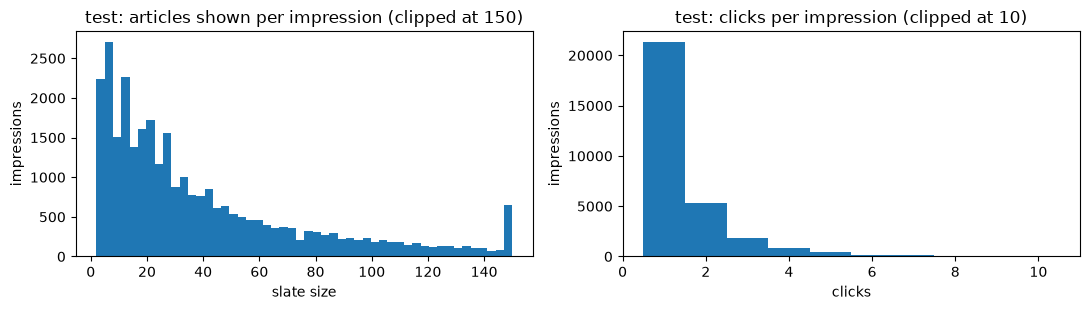

In [15]:
quantiles = [0.0, 0.25, 0.5, 0.75, 0.9, 0.99, 1.0]
target_slates = slate_sizes[TARGET_SPLIT]
display(target_slates.select(
    *[pl.col("slate_size").quantile(q).alias(f"size_q{int(q * 100)}") for q in quantiles],
    pl.col("clicks").mean().alias("mean_clicks"),
    pl.col("clicks").max().alias("max_clicks"),
))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(target_slates["slate_size"].clip(upper_bound=150), bins=50)
axes[1].hist(target_slates["clicks"].clip(upper_bound=10), bins=np.arange(0.5, 11.5))
axes[0].set(title=f"{TARGET_SPLIT}: articles shown per impression (clipped at 150)", xlabel="slate size", ylabel="impressions")
axes[1].set(title=f"{TARGET_SPLIT}: clicks per impression (clipped at 10)", xlabel="clicks", ylabel="impressions")
plt.tight_layout()
plt.show()

## 2.2 Causal Click Histories

`request_profiles_<split>` stores, for every impression, the article rows the user clicked
**strictly before** that impression. RR4 reads the newest `HISTORY_CAP` of them. History length
also defines the cohorts used in section 5.3.

In [16]:
def load_profiles(split, impression_ids=None):
    """Map each impression to the article rows its user clicked strictly before the impression."""
    profiles = (
        pl.scan_parquet(RUN / f"request_profiles_{split}" / "*.parquet")
        .select("impression_uid", "full_history_rows")
    )
    if impression_ids is not None:
        profiles = profiles.filter(pl.col("impression_uid").is_in(list(impression_ids)))
    profiles = profiles.collect()
    return dict(zip(profiles["impression_uid"].to_list(), profiles["full_history_rows"].to_list()))


def encode_histories(impression_ids, profiles):
    """Left-padded [impressions, HISTORY_CAP] article rows with the newest click last."""
    histories = np.zeros((len(impression_ids), HISTORY_CAP), dtype=np.int64)
    for index, uid in enumerate(impression_ids):
        history = profiles[uid][-HISTORY_CAP:]
        if len(history):
            histories[index, -len(history):] = history
    return histories


HISTORY_BINS = [(0, 0, "0 clicks"), (1, 5, "1-5 clicks"), (6, 20, "6-20 clicks"), (21, None, "21+ clicks")]
COHORT_ORDER = [label for _, _, label in HISTORY_BINS]

target_profiles = load_profiles(TARGET_SPLIT)
history_length = pl.DataFrame({
    "impression_uid": list(target_profiles),
    "history_length": [len(rows) for rows in target_profiles.values()],
})
cohort = pl.lit(None, dtype=pl.Utf8)
for low, high, label in reversed(HISTORY_BINS):
    condition = pl.col("history_length") >= low if high is None else pl.col("history_length").is_between(low, high)
    cohort = pl.when(condition).then(pl.lit(label)).otherwise(cohort)
target_cohorts = (
    history_length.with_columns(cohort.alias("cohort"))
    .join(target_slates.select("impression_uid"), on="impression_uid", how="semi")
)
if target_cohorts.height != target_slates.height:
    raise ValueError(f"{TARGET_SPLIT}: some impressions have no request profile")

display(
    target_cohorts.group_by("cohort")
    .agg(pl.len().alias("impressions"), pl.col("history_length").median().alias("median_history"))
    .with_columns((pl.col("impressions") / pl.col("impressions").sum()).alias("share"))
    .sort(pl.col("cohort").replace_strict({c: i for i, c in enumerate(COHORT_ORDER)}))
)

cohort,impressions,median_history,share
str,u32,f64,f64
"""0 clicks""",94,0.0,0.003105
"""1-5 clicks""",3128,4.0,0.103337
"""6-20 clicks""",10305,12.0,0.340436
"""21+ clicks""",16743,47.0,0.553122


## 2.3 Article Inputs

All article inputs are indexed by `article_row`; row 0 is padding. Every logged candidate must map
to an article row, otherwise RR4 cannot encode it.

In [17]:
article_index = pl.read_parquet(
    REPRESENTATIONS / "article_index.parquet",
    columns=["news_code", "article_row", "category_code", "subcategory_code"],
)
news_to_row = dict(zip(article_index["news_code"].to_list(), article_index["article_row"].to_list()))

text_vectors = np.load(REPRESENTATIONS / "text64.npy", mmap_mode="r")
entity_vectors = np.load(REPRESENTATIONS / "article_entity100.npy", mmap_mode="r")
N_ARTICLES = text_vectors.shape[0]

# Category and subcategory codes per article row (0 = padding / unknown)
article_category = np.zeros(N_ARTICLES, dtype=np.int64)
article_subcategory = np.zeros(N_ARTICLES, dtype=np.int64)
article_category[article_index["article_row"].to_numpy()] = article_index["category_code"].to_numpy()
article_subcategory[article_index["article_row"].to_numpy()] = article_index["subcategory_code"].to_numpy()
print(f"{N_ARTICLES:,} article rows; {article_category.max()} categories; {article_subcategory.max()} subcategories")

for split in (TRAIN_SPLIT, TARGET_SPLIT):
    features, _ = scan_split(split)
    codes = features.select(pl.col("news_code").unique()).collect()["news_code"]
    unmapped = codes.filter(~codes.is_in(list(news_to_row)))
    if unmapped.len():
        raise ValueError(f"{split}: {unmapped.len()} logged articles have no article row")
    print(f"{split}: all {codes.len():,} logged articles map to an article row")

51,283 article rows; 17 categories; 257 subcategories
train: all 13,536 logged articles map to an article row
test: all 6,144 logged articles map to an article row


# 3. Rule-Based Baselines

Both rules read causal features that feature engineering already computed, so they have no
trainable parameters. They are copied unchanged from `5_02_Reranking/1_Baseline`.

**Popularity** (`RR_popularity_baseline.ipynb`). For candidate $a$ at impression time $t$:

$$s(a,t) = \frac{c_{a,<t} + \alpha\, p_{<t}}{e_{a,<t} + \alpha}$$

where $c$ and $e$ are the article's earlier clicks and exposures and $p$ is the expanding global
CTR. Every user gets the same score.

**Content similarity** (`RR_content_similarity_baseline.ipynb`). The cosine between the candidate's
entity vector and the user's causal clicked-history entity profile (the rule selected on validation
there). A candidate with no valid vector scores $-2$, below every valid cosine in $[-1, 1]$; a user
with no profile falls back to the popularity score.

In [18]:
MISSING_SCORE = -2.0
POPULARITY_COLUMNS = ["smoothed_prior_article_ctr"]
CONTENT_COLUMNS = ["smoothed_prior_article_ctr", "entity_cosine", "entity_match_valid", "no_entity_profile"]


def popularity_score(frame):
    """Score each candidate by its causal smoothed article CTR."""
    return frame["smoothed_prior_article_ctr"].to_numpy(dtype=float)


def content_score(frame):
    """Entity cosine to the causal profile; popularity when the user has no entity profile."""
    prior = frame["smoothed_prior_article_ctr"].to_numpy(dtype=float)
    entity = frame["entity_cosine"].to_numpy(dtype=float)
    entity_valid = frame["entity_match_valid"].to_numpy(dtype=bool)
    no_entity_profile = frame["no_entity_profile"].to_numpy(dtype=bool)
    return np.where(no_entity_profile, prior, np.where(entity_valid, entity, MISSING_SCORE))


missing_columns = sorted(set(CONTENT_COLUMNS) - set(FEATURES))
if missing_columns:
    raise ValueError(f"Baseline columns missing from the feature schema: {missing_columns}")

# 4. Train the RR4 Reranker

## 4.1 Sample Training Impressions

Copied from `RR_4_branch_interaction.ipynb`. Whole impressions are sampled because both listwise
losses compare candidates **within** an impression. Listwise losses need at least one click and
one non-click, so other impressions are dropped, and slates are capped at `MAX_CANDIDATES` (every
click kept, negatives sampled). 10% of impressions are held out to pick the best epoch, so
validation and test are never seen during training.

Two training frames are built, as in RR_4:

- the **`PREPROCESSOR_IMPRESSIONS` sample**: its fit part is what the tabular preprocessor is
  fitted on (RR_4 section 3.5);
- the **full training set**: what the final model is trained on (RR_4 stage 3).

In [19]:
def sample_train_impressions(max_impressions, columns):
    """Sample whole training impressions, then load every retained candidate in them."""
    feature_files = sorted((RUN / "ranking_features_train").glob("*.parquet"))
    label_files = sorted((RUN / "labels_train").glob("*.parquet"))
    impression_ids = (
        pl.scan_parquet(label_files)
        .select("impression_uid").unique().sort("impression_uid")
        .collect()["impression_uid"].to_numpy()
    )
    rng = np.random.default_rng(SEED)
    chosen = rng.choice(impression_ids, size=min(max_impressions, len(impression_ids)), replace=False)

    keys = ["impression_uid", "news_code"]
    read_columns = list(dict.fromkeys([*keys, "prior_article_exposures", *columns]))
    features = (
        pl.scan_parquet(feature_files)
        .filter(pl.col("impression_uid").is_in(chosen))
        .select(read_columns).collect().to_pandas()
    )
    labels = (
        pl.scan_parquet(label_files)
        .filter(pl.col("impression_uid").is_in(chosen))
        .select(*keys, "clicked").collect().to_pandas()
    )
    train = features.merge(labels, on=keys, how="inner", validate="one_to_one")
    if not len(train) == len(features) == len(labels):
        raise ValueError("Training feature and label keys do not match")
    return train.sort_values(keys).reset_index(drop=True)


def cap_slates(frame, max_candidates):
    """Keep every click and at most `max_candidates` rows per impression (negatives sampled)."""
    rng = np.random.default_rng(SEED)
    keep = []
    for rows in frame.groupby("impression_uid", sort=False).indices.values():
        if len(rows) <= max_candidates:
            keep.append(rows)
            continue
        clicked = rows[frame["clicked"].to_numpy()[rows] == 1]
        unclicked = rows[frame["clicked"].to_numpy()[rows] == 0]
        n_negatives = max(max_candidates - len(clicked), 1)
        keep.append(np.concatenate([clicked, rng.choice(unclicked, size=min(n_negatives, len(unclicked)), replace=False)]))
    return frame.iloc[np.sort(np.concatenate(keep))].reset_index(drop=True)


def prepare_training_slates(max_impressions):
    """Sample, keep usable slates, cap them and split off the holdout impressions."""
    train = sample_train_impressions(max_impressions, FEATURES)
    slate_stats = train.groupby("impression_uid")["clicked"].agg(["sum", "size"])
    usable = slate_stats.index[(slate_stats["sum"] > 0) & (slate_stats["sum"] < slate_stats["size"])]
    train = cap_slates(train[train["impression_uid"].isin(usable)].reset_index(drop=True), MAX_CANDIDATES)

    impression_ids = train["impression_uid"].drop_duplicates().to_numpy()
    holdout_ids = np.random.default_rng(SEED).choice(
        impression_ids, size=int(HOLDOUT_FRACTION * len(impression_ids)), replace=False
    )
    in_holdout = train["impression_uid"].isin(holdout_ids)
    return train[~in_holdout].reset_index(drop=True), train[in_holdout].reset_index(drop=True)


if not RR4_LOADED:
    preprocessor_fit, _ = prepare_training_slates(PREPROCESSOR_IMPRESSIONS)
    fit, holdout = prepare_training_slates(FULL_TRAIN_IMPRESSIONS or 10**9)
    print(f"Preprocessor sample: {preprocessor_fit['impression_uid'].nunique():,} fit impressions")
    print(f"Full training set: {fit['impression_uid'].nunique():,} fit / "
          f"{holdout['impression_uid'].nunique():,} holdout impressions, {len(fit) + len(holdout):,} candidates")
    print(f"Fit click rate: {fit['clicked'].mean():.4f}")

## 4.2 RR4 Model

Copied from `RR_4_branch_interaction.ipynb`. Only the `+metadata` branches are switched on.

```text
news vector = Linear+LayerNorm( text64 ; category emb ; subcategory emb ; Linear(entity100) )
user vector = self-attention over the newest 30 clicked news vectors -> additive attention pool
score       = MLP( [tabular features ; candidate news vector ; user vector] ) -> logit
```

**Additive attention** scores each element with a learned query vector and returns the weighted
sum. It pools the attended click history into one user vector.

In [20]:
class AdditiveAttention(nn.Module):
    """Pool a sequence of history states into one user vector with learned relevance weights."""

    def __init__(self, dim):
        super().__init__()
        self.proj = nn.Linear(dim, dim)
        self.query = nn.Parameter(torch.randn(dim) * 0.02)

    def forward(self, states, padding_mask):
        # states: [batch, history, dim]; padding_mask: [batch, history], True = padding
        all_padded = padding_mask.all(dim=1)
        safe_mask = padding_mask.clone()
        safe_mask[all_padded, 0] = False                       # softmax needs one open slot

        scores = torch.tanh(self.proj(states)) @ self.query    # [batch, history]
        weights = torch.softmax(scores.masked_fill(safe_mask, -1e9), dim=1)
        weights = weights.masked_fill(padding_mask, 0.0)
        weights = weights / weights.sum(dim=1, keepdim=True).clamp(min=1e-8)
        return (weights.unsqueeze(-1) * states).sum(dim=1)     # [batch, dim]

**`NewsEncoder`** maps article rows to `MODEL_DIM` news vectors. The frozen text vector is
concatenated with learned category and subcategory embeddings and a projected entity vector.

In [21]:
class NewsEncoder(nn.Module):
    """Map article rows to MODEL_DIM news vectors from the enabled article inputs."""

    def __init__(self, config):
        super().__init__()
        if config["title_encoder"]:
            raise NotImplementedError("This notebook's RR4 architecture does not use the title encoder")
        self.config = config
        self.register_buffer("text", torch.from_numpy(np.array(text_vectors, dtype=np.float32)), persistent=False)
        width = self.text.shape[1]

        if config["metadata"]:
            self.register_buffer("entity", torch.from_numpy(np.array(entity_vectors, dtype=np.float32)), persistent=False)
            self.register_buffer("category", torch.from_numpy(article_category), persistent=False)
            self.register_buffer("subcategory", torch.from_numpy(article_subcategory), persistent=False)
            self.category_embedding = nn.Embedding(int(article_category.max()) + 1, 16, padding_idx=0)
            self.subcategory_embedding = nn.Embedding(int(article_subcategory.max()) + 1, 16, padding_idx=0)
            self.entity_projection = nn.Linear(self.entity.shape[1], 32)
            width += 16 + 16 + 32

        self.output = nn.Sequential(nn.Linear(width, MODEL_DIM), nn.LayerNorm(MODEL_DIM))

    def forward(self, rows):
        # Encode each distinct article in the batch once, then scatter back to every position
        unique_rows, inverse = torch.unique(rows, return_inverse=True)
        parts = [self.text[unique_rows]]
        if self.config["metadata"]:
            parts += [
                self.category_embedding(self.category[unique_rows]),
                self.subcategory_embedding(self.subcategory[unique_rows]),
                self.entity_projection(self.entity[unique_rows]),
            ]
        return self.output(torch.cat(parts, dim=-1))[inverse]   # rows.shape + [MODEL_DIM]

**`UserEncoder`** runs multi-head self-attention and a feed-forward block over the clicked news
vectors, then pools them with additive attention. Users with no history get a learned default
vector. The position, candidate-pooling and short-term branches are kept switchable as in RR_4 but
are off here.

In [22]:
class UserEncoder(nn.Module):
    """Encode the click history into per-candidate user vectors."""

    def __init__(self, config):
        super().__init__()
        self.config = config
        if config["position"]:
            self.position_embedding = nn.Embedding(HISTORY_CAP, MODEL_DIM)
        self.self_attention = nn.MultiheadAttention(MODEL_DIM, ATTENTION_HEADS, dropout=ATTENTION_DROPOUT, batch_first=True)
        self.norm1 = nn.LayerNorm(MODEL_DIM)
        self.feed_forward = nn.Sequential(
            nn.Linear(MODEL_DIM, 4 * MODEL_DIM),
            nn.ReLU(),
            nn.Dropout(ATTENTION_DROPOUT),
            nn.Linear(4 * MODEL_DIM, MODEL_DIM),
        )
        self.norm2 = nn.LayerNorm(MODEL_DIM)
        self.pool = AdditiveAttention(MODEL_DIM)
        self.default_user = nn.Parameter(torch.zeros(MODEL_DIM))
        if config["short_term"]:
            self.short_term = nn.GRU(MODEL_DIM, MODEL_DIM, batch_first=True)
            self.gate = nn.Linear(2 * MODEL_DIM, MODEL_DIM)

    @property
    def output_dim(self):
        return MODEL_DIM * (2 if self.config["candidate_pooling"] else 1)

    def forward(self, history, padding_mask, candidates):
        # history: [B, H, D]; padding_mask: [B, H] (True = padding); candidates: [B, W, D]
        empty = padding_mask.all(dim=1)
        safe_mask = padding_mask.clone()
        safe_mask[empty, -1] = False

        if self.config["position"]:
            ranks = torch.arange(HISTORY_CAP - 1, -1, -1, device=history.device)
            history = history + self.position_embedding(ranks)

        attended, _ = self.self_attention(history, history, history, key_padding_mask=safe_mask, need_weights=False)
        states = self.norm1(history + attended)
        states = self.norm2(states + self.feed_forward(states))
        states = states.masked_fill(padding_mask.unsqueeze(-1), 0.0)

        user = self.pool(states, padding_mask)
        if self.config["short_term"]:
            _, short = self.short_term(states[:, -SHORT_TERM_CAP:])
            short = short.squeeze(0)
            gate = torch.sigmoid(self.gate(torch.cat([user, short], dim=1)))
            user = gate * user + (1 - gate) * short
        user = torch.where(empty.unsqueeze(1), self.default_user.unsqueeze(0), user)
        user = user.unsqueeze(1).expand(-1, candidates.shape[1], -1)   # [B, W, D]

        if not self.config["candidate_pooling"]:
            return user
        scores = candidates @ states.transpose(1, 2) / np.sqrt(MODEL_DIM)       # [B, W, H]
        scores = scores.masked_fill(safe_mask.unsqueeze(1), -1e9)
        weights = torch.softmax(scores, dim=-1).masked_fill(padding_mask.unsqueeze(1), 0.0)
        return torch.cat([user, weights @ states], dim=-1)

**`BranchReranker`** concatenates the enabled branches and scores them with a two-layer MLP:
`[tabular ; candidate news vector ; user vector] -> Dense 256 -> ReLU -> Dropout -> Dense 64 -> ReLU -> Dropout -> logit`.

In [23]:
class BranchReranker(nn.Module):
    """Score candidates from the enabled tabular, news and user branches."""

    def __init__(self, config, tabular_width):
        super().__init__()
        if config["user_encoder"] and not config["text"]:
            raise ValueError("The user encoder needs the news encoder (text=True)")
        if not (config["tabular"] or config["text"]):
            raise ValueError("At least one of the tabular or text branches must be on")
        self.config = config
        width = tabular_width if config["tabular"] else 0
        if config["text"]:
            self.news_encoder = NewsEncoder(config)
            width += MODEL_DIM
        if config["user_encoder"]:
            self.user_encoder = UserEncoder(config)
            width += self.user_encoder.output_dim

        layers = []
        for hidden in HIDDEN_DIMS:
            layers.extend([nn.Linear(width, hidden), nn.ReLU(), nn.Dropout(DROPOUT)])
            width = hidden
        layers.append(nn.Linear(width, 1))
        self.scorer = nn.Sequential(*layers)

    def forward(self, tabular, candidate_rows, history_rows):
        # tabular: [B, W, T]; candidate_rows: [B, W]; history_rows: [B, H] -> logits [B, W]
        parts = [tabular] if self.config["tabular"] else []
        if self.config["text"]:
            candidates = self.news_encoder(candidate_rows)
            parts.append(candidates)
            if self.config["user_encoder"]:
                history = self.news_encoder(history_rows)
                parts.append(self.user_encoder(history, history_rows.eq(0), candidates))
        return self.scorer(torch.cat(parts, dim=-1)).squeeze(-1)

## 4.3 Preprocessor and Impression Batches

The preprocessor median-imputes and standardises numeric features and one-hot encodes the
categoricals. It is fitted on the preprocessor sample's fit impressions only, as in RR_4.

Training and the holdout check work on padded impression batches: `rows` and `mask` are
`[impressions, candidates]`, and each impression's history is encoded once and shared by all of its
candidates. Tabular features are preprocessed one batch at a time, which keeps memory flat on the
full training set.

In [24]:
def build_preprocessor():
    """Median-impute and standardise numeric inputs; mode-impute and one-hot encode categoricals."""
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("numeric", numeric, NUMERIC),
        ("categorical", categorical, CATEGORICAL),
    ])


if RR4_LOADED:
    preprocessor = joblib.load(PREPROCESSOR_PATH)
    TABULAR_WIDTH = RR4_CHECKPOINT_META["tabular_width"]
    print("Loaded preprocessor:", PREPROCESSOR_PATH)
else:
    preprocessor = build_preprocessor().fit(preprocessor_fit[FEATURES])
    joblib.dump(preprocessor, PREPROCESSOR_PATH)
    TABULAR_WIDTH = preprocessor.transform(preprocessor_fit[FEATURES].head(1)).shape[1]
    print("Saved preprocessor:", PREPROCESSOR_PATH)
print(f"Tabular width: {TABULAR_WIDTH}")


def build_impression_data(frame, precompute_tabular=True):
    """Arrays for padded impression batches over a training frame."""
    uids = frame["impression_uid"].drop_duplicates().tolist()
    candidate_rows = frame["news_code"].map(news_to_row)
    if candidate_rows.isna().any():
        raise ValueError("A candidate is missing its article row")
    return {
        "groups": [rows.astype(np.int64) for rows in frame.groupby("impression_uid", sort=False).indices.values()],
        "histories": torch.from_numpy(encode_histories(uids, load_profiles(TRAIN_SPLIT, uids))),
        "tabular": (torch.from_numpy(preprocessor.transform(frame[FEATURES]).astype(np.float32, copy=False))
                    if precompute_tabular else None),
        "features": None if precompute_tabular else frame[FEATURES].reset_index(drop=True),
        "candidates": torch.from_numpy(candidate_rows.to_numpy(np.int64)),
        "labels": torch.from_numpy(frame["clicked"].to_numpy(np.float32)),
    }


def impression_batches(data, order):
    """Yield (tabular, candidates, histories, labels, mask) for batches of impressions."""
    for start in range(0, len(order), BATCH_IMPRESSIONS):
        batch = order[start:start + BATCH_IMPRESSIONS]
        groups = [data["groups"][index] for index in batch]
        width = max(len(group) for group in groups)
        rows = torch.zeros((len(batch), width), dtype=torch.long)
        mask = torch.zeros((len(batch), width), dtype=torch.bool)
        for position, group in enumerate(groups):
            rows[position, :len(group)] = torch.from_numpy(group)
            mask[position, :len(group)] = True
        if data["tabular"] is not None:
            tabular = data["tabular"][rows]
        else:
            raw = data["features"].iloc[rows.reshape(-1).numpy()]
            tabular = torch.from_numpy(preprocessor.transform(raw).astype(np.float32, copy=False)).reshape(*rows.shape, -1)
        yield (
            tabular.to(DEVICE),
            data["candidates"][rows].to(DEVICE),
            data["histories"][torch.as_tensor(batch)].to(DEVICE),
            (data["labels"][rows] * mask).to(DEVICE),   # padding never counts as a click
            mask.to(DEVICE),
        )


if not RR4_LOADED:
    fit_data = build_impression_data(fit, precompute_tabular=False)
    holdout_data = build_impression_data(holdout, precompute_tabular=False)

Loaded preprocessor: /Users/numkoos/Downloads/v3-mindsmall/5_Models/5_03_Pipeline_Evaluation/artifacts/reranker_logged_slates/reranker/preprocessor.joblib
Tabular width: 246


## 4.4 Losses and Training Loop

The selected loss is `softmax+lambda_ndcg` = `0.5 * softmax + 0.5 * lambda_ndcg`:

- **Listwise softmax**: for each click, cross-entropy of that click against every unclicked
  candidate in its impression: $-\log \frac{e^{s^+}}{e^{s^+} + \sum_{j \in neg} e^{s_j}}$.
  It favours MRR-style "click on top" behaviour.
- **LambdaNDCG@K**: a RankNet loss on (click, non-click) pairs weighted by how much swapping them
  would change nDCG@K, so it concentrates on the top-K order the metric reads.

Each epoch shuffles the fit impressions. After every epoch the model ranks the holdout impressions'
retained candidates, and the epoch with the best holdout nDCG@10 is kept. Training stops once the
holdout score has not improved for `PATIENCE` epochs.

In [25]:
def listwise_softmax_loss(logits, labels, mask):
    """Mean over clicks of -log softmax(click vs. all unclicked candidates in its impression)."""
    positive = (labels > 0) & mask
    negative = (labels == 0) & mask
    negative_lse = torch.logsumexp(logits.masked_fill(~negative, float("-inf")), dim=1, keepdim=True)
    log_probability = logits - torch.logaddexp(logits, negative_lse)
    return -(log_probability * positive).sum() / positive.sum().clamp_min(1)


def lambda_ndcg_loss(logits, labels, mask, k=NDCG_K):
    """RankNet loss weighted by detached |Delta nDCG@k| for every (click, non-click) pair."""
    masked_logits = logits.masked_fill(~mask, float("-inf"))
    ranks = masked_logits.argsort(dim=1, descending=True).argsort(dim=1).add(1).detach()
    gains = (torch.pow(2.0, labels) - 1.0) * mask
    discounts = (1.0 / torch.log2(ranks.float() + 1.0)) * (ranks <= k) * mask

    ideal_labels = labels.masked_fill(~mask, float("-inf")).sort(dim=1, descending=True).values
    ideal_mask = torch.isfinite(ideal_labels)
    ideal_labels = ideal_labels.clamp_min(0)
    positions = torch.arange(1, logits.shape[1] + 1, device=logits.device)
    ideal_discounts = (1.0 / torch.log2(positions.float() + 1.0)) * (positions <= k)
    idcg = ((torch.pow(2.0, ideal_labels) - 1.0) * ideal_discounts * ideal_mask).sum(dim=1).clamp_min(1e-12)

    score_diff = logits.unsqueeze(2) - logits.unsqueeze(1)
    delta_ndcg = ((gains.unsqueeze(2) - gains.unsqueeze(1)) * (discounts.unsqueeze(2) - discounts.unsqueeze(1))).abs()
    weights = delta_ndcg / idcg[:, None, None]
    valid_pairs = (labels.unsqueeze(2) > labels.unsqueeze(1)) & mask.unsqueeze(2) & mask.unsqueeze(1)
    weights = weights * valid_pairs
    return (F.softplus(-score_diff) * weights).sum() / weights.sum().clamp_min(1e-12)


def combined_loss(**weights):
    """Weighted sum of base losses, e.g. combined_loss(softmax=0.5, lambda_ndcg=0.5)."""
    base = {"softmax": listwise_softmax_loss, "lambda_ndcg": lambda_ndcg_loss}

    def loss(logits, labels, mask):
        return sum(weight * base[name](logits, labels, mask) for name, weight in weights.items())
    return loss


LOSSES = {"softmax+lambda_ndcg": combined_loss(softmax=0.5, lambda_ndcg=0.5)}


def batch_ndcg(logits, labels, mask, k=10):
    """Mean nDCG@k over a batch of impressions (retained candidates only)."""
    order = logits.masked_fill(~mask, float("-inf")).argsort(dim=1, descending=True)[:, :k]
    discounts = 1.0 / torch.log2(torch.arange(2, order.shape[1] + 2, device=logits.device).float())
    dcg = (labels.gather(1, order) * discounts).sum(dim=1)
    ideal = (labels.masked_fill(~mask, 0).sort(dim=1, descending=True).values[:, :order.shape[1]] * discounts).sum(dim=1)
    return (dcg / ideal.clamp_min(1e-12)).mean().item()


def train_model(config, loss_name, fit_data, holdout_data, epochs=EPOCHS, patience=None):
    """Train one architecture with one loss; return the best-holdout-epoch model."""
    torch.manual_seed(SEED)
    model = BranchReranker(config, TABULAR_WIDTH).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_fn = LOSSES[loss_name]
    rng = np.random.default_rng(SEED)
    best = {"ndcg": -1.0, "epoch": 0, "state": None}
    history = []

    for epoch in range(1, epochs + 1):
        started = time.monotonic()
        model.train()
        losses = []
        for tabular, candidates, histories, labels, mask in impression_batches(fit_data, rng.permutation(len(fit_data["groups"]))):
            optimizer.zero_grad()
            loss = loss_fn(model(tabular, candidates, histories), labels, mask)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())

        model.eval()
        with torch.no_grad():
            holdout_scores = [
                batch_ndcg(model(tabular, candidates, histories), labels, mask)
                for tabular, candidates, histories, labels, mask in impression_batches(holdout_data, np.arange(len(holdout_data["groups"])))
            ]
        holdout_ndcg = float(np.mean(holdout_scores))
        history.append({"epoch": epoch, "loss": float(np.mean(losses)), "holdout_ndcg_at_10": holdout_ndcg,
                        "minutes": (time.monotonic() - started) / 60})
        print(f"  epoch {epoch}/{epochs}: {loss_name} loss {np.mean(losses):.4f}, holdout nDCG@10 {holdout_ndcg:.4f}")
        if holdout_ndcg > best["ndcg"]:
            best = {"ndcg": holdout_ndcg, "epoch": epoch,
                    "state": {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}}
        elif patience is not None and epoch - best["epoch"] >= patience:
            print(f"  early stopping: no holdout improvement for {patience} epochs; keeping epoch {best['epoch']}")
            break

    model.load_state_dict(best["state"])
    model.best_epoch, model.best_holdout_ndcg = best["epoch"], best["ndcg"]
    model.history = history
    return model

## 4.5 Train or Load RR4

In [26]:
if RR4_LOADED:
    model = BranchReranker(CONFIG, RR4_CHECKPOINT_META["tabular_width"]).to(DEVICE)
    model.load_state_dict(RR4_CHECKPOINT_META["state_dict"], strict=True)
    model.best_epoch = RR4_CHECKPOINT_META["best_epoch"]
    model.best_holdout_ndcg = RR4_CHECKPOINT_META["holdout_ndcg"]
    model.history = RR4_CHECKPOINT_META.get("history", [])
    print("Loaded RR4:", RR4_CHECKPOINT_PATH)
else:
    started = time.monotonic()
    model = train_model(CONFIG, LOSS_NAME, fit_data, holdout_data, epochs=EPOCHS, patience=PATIENCE)
    torch.save(
        {
            "state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
            "config": CONFIG,
            "loss": LOSS_NAME,
            "tabular_width": TABULAR_WIDTH,
            "features": FEATURES,
            "training": TRAINING_SETTINGS,
            "best_epoch": int(model.best_epoch),
            "holdout_ndcg": float(model.best_holdout_ndcg),
            "history": model.history,
            "seed": SEED,
        },
        RR4_CHECKPOINT_PATH,
    )
    print(f"Saved RR4: {RR4_CHECKPOINT_PATH} ({(time.monotonic() - started) / 60:.1f} min)")
    del fit_data, holdout_data

model.eval()
print(f"Best epoch: {model.best_epoch} (holdout nDCG@10 {model.best_holdout_ndcg:.4f})")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
if model.history:
    display(pd.DataFrame(model.history).round(4))

Loaded RR4: /Users/numkoos/Downloads/v3-mindsmall/5_Models/5_03_Pipeline_Evaluation/artifacts/reranker_logged_slates/reranker/model.pt
Best epoch: 8 (holdout nDCG@10 0.5263)
Trainable parameters: 182,817


,epoch,loss,holdout_ndcg_at_10,minutes
0,1,1.6569,0.5110,0.7806
1,2,1.6237,0.5168,0.7440
2,3,1.6110,0.5199,0.8043
3,4,1.5985,0.5196,0.7813
4,5,1.5894,0.5228,0.7112
5,6,1.5803,0.5237,0.9042
6,7,1.5736,0.5255,0.7808
7,8,1.5674,0.5263,0.7476
8,9,1.5600,0.5241,0.7896
9,10,1.5547,0.5241,0.7677


# 5. Score and Evaluate the Logged Slates

Each model writes one score per logged (impression, article) pair of the target split to
`MODEL_DIR/scores/<model>_<split>_scores.parquet`. RR4 scores pointwise: each candidate is scored
as a one-article slate with its own history, so candidates never influence each other.

`rr_evaluation.py` rejects incomplete or duplicate score files and breaks ties by ascending
`news_code`. Reported metrics (over complete logged slates, at each cutoff in `K_VALUES`):

| Metric | Meaning |
|---|---|
| `mrr` | Reciprocal rank of the first click |
| `ndcg_at_k` | Binary-click nDCG over the top `k` |
| `recall_at_k` | Share of an impression's clicks in the top `k`, averaged over impressions |
| `click_retention_at_k` | Pooled share of all clicks in the top `k` |
| `engaged_impression_rate_at_k` | Share of impressions with at least one click in the top `k` |
| `observed_ctr_at_k` | Clicks per article in the top `k` (lift is relative to popularity) |

## 5.1 Overall Results

In [27]:
def rr4_predictor(model, profiles):
    """Wrap the trained model and a split's histories as a predict(frame) function."""
    def predict(frame):
        uids = frame["impression_uid"].drop_duplicates().tolist()
        histories = encode_histories(uids, profiles)
        history_index = frame["impression_uid"].map(pd.Series(np.arange(len(uids)), index=uids)).to_numpy()
        tabular = preprocessor.transform(frame[FEATURES]).astype(np.float32, copy=False)
        candidates = np.array(frame["news_code"].map(news_to_row), dtype=np.int64)

        scores = []
        with torch.no_grad():
            for start in range(0, len(frame), SCORING_BATCH_ROWS):
                stop = start + SCORING_BATCH_ROWS
                logits = model(
                    torch.from_numpy(tabular[start:stop]).unsqueeze(1).to(DEVICE),
                    torch.from_numpy(candidates[start:stop]).unsqueeze(1).to(DEVICE),
                    torch.from_numpy(histories[history_index[start:stop]]).to(DEVICE),
                )
                scores.append(torch.sigmoid(logits.squeeze(1)).cpu().numpy())
        return np.concatenate(scores)
    return predict


SCORERS = {
    POPULARITY_MODEL: (popularity_score, POPULARITY_COLUMNS),
    CONTENT_MODEL: (content_score, CONTENT_COLUMNS),
    RR4_MODEL: (rr4_predictor(model, target_profiles), FEATURES),
}
evaluator = RerankingEvaluator(split=TARGET_SPLIT, feature_run=RUN)


def score_path(model_name):
    return SCORE_DIR / f"{model_name}_{TARGET_SPLIT}_scores.parquet"


overall_rows, timings = [], []
for model_name in MODEL_NAMES:
    started = time.monotonic()
    predict, columns = SCORERS[model_name]
    write_scores(predict, split=TARGET_SPLIT, feature_run=RUN, output_path=score_path(model_name), columns=columns)
    result = evaluator.evaluate(score_path(model_name), model_name=model_name, k_values=K_VALUES)
    overall_rows.append(result)
    timings.append({"model": model_name, "seconds": round(time.monotonic() - started, 1)})
    print(f"Evaluated {model_name}: nDCG@10 {result['ndcg_at_10'][0]:.4f}")

overall = compare_results(overall_rows, baseline_model=POPULARITY_MODEL)
display(pl.DataFrame(timings))

Evaluated popularity_smoothed_prior_article_ctr: nDCG@10 0.3557
Evaluated content_entity_cosine: nDCG@10 0.3056
Evaluated attention_reranker: nDCG@10 0.4444


model,seconds
str,f64
"""popularity_smoothed_prior_arti…",1.9
"""content_entity_cosine""",1.6
"""attention_reranker""",23.7


In [28]:
def metric_table(results, metrics):
    """Models as rows, one column per metric@k, best model first."""
    return (
        results.sort(f"ndcg_at_{K_VALUES[1]}", descending=True)
        .with_columns(pl.col("model").replace_strict(MODEL_LABELS))
        .select("model", "impressions", *[f"{m}_at_{k}" for m in metrics for k in K_VALUES])
    )


print(f"{TARGET_SPLIT.upper()}: ranking accuracy")
display(overall.with_columns(pl.col("model").replace_strict(MODEL_LABELS)).select("model", "impressions", "mrr").sort("mrr", descending=True))
display(metric_table(overall, ["ndcg", "recall"]))
print(f"{TARGET_SPLIT.upper()}: clicks reached")
display(metric_table(overall, ["engaged_impression_rate", "observed_ctr"]))
display(
    overall.with_columns(pl.col("model").replace_strict(MODEL_LABELS))
    .select("model", *[f"observed_ctr_at_{k}_lift_pct_vs_baseline" for k in K_VALUES])
)

TEST: ranking accuracy


model,impressions,mrr
str,i64,f64
"""RR4 attention reranker""",30270,0.410056
"""Popularity (rule)""",30270,0.323149
"""Content similarity (rule)""",30270,0.268094


model,impressions,ndcg_at_5,ndcg_at_10,ndcg_at_30,recall_at_5,recall_at_10,recall_at_30
str,i64,f64,f64,f64,f64,f64,f64
"""RR4 attention reranker""",30270,0.384142,0.444436,0.505092,0.510686,0.681804,0.901365
"""Popularity (rule)""",30270,0.292374,0.355655,0.431714,0.408817,0.590234,0.870441
"""Content similarity (rule)""",30270,0.245041,0.305575,0.381081,0.361378,0.535904,0.816453


TEST: clicks reached


model,impressions,engaged_impression_rate_at_5,engaged_impression_rate_at_10,engaged_impression_rate_at_30,observed_ctr_at_5,observed_ctr_at_10,observed_ctr_at_30
str,i64,f64,f64,f64,f64,f64,f64
"""RR4 attention reranker""",30270,0.597225,0.766138,0.942716,0.139198,0.103039,0.062365
"""Popularity (rule)""",30270,0.484539,0.675884,0.920515,0.109348,0.087402,0.059303
"""Content similarity (rule)""",30270,0.416188,0.606046,0.876016,0.09162,0.075681,0.054109


model,observed_ctr_at_5_lift_pct_vs_baseline,observed_ctr_at_10_lift_pct_vs_baseline,observed_ctr_at_30_lift_pct_vs_baseline
str,f64,f64,f64
"""RR4 attention reranker""",27.298364,17.891054,5.164948
"""Popularity (rule)""",0.0,0.0,0.0
"""Content similarity (rule)""",-16.212321,-13.409962,-8.757841


## 5.2 Comparison with the RR_4 Run

The same model trained in `RR_4_branch_interaction.ipynb` (stage 3) recorded these metrics. When
this notebook trains with identical data, preprocessing, seed and loop, the numbers should agree
closely; small differences can come from running on a different device (GPU kernels are not
bit-for-bit deterministic). A large gap means the data or settings differ.

In [29]:
RR4_REFERENCE = {  # RR_4_branch_interaction.ipynb, branch_plus_metadata__softmax_plus_lambda_ndcg__full_data
    "validation": {"best_epoch": 7, "holdout_ndcg": 0.5270, "mrr": 0.429742, "ndcg_at_5": 0.407457,
                   "ndcg_at_10": 0.462785, "recall_at_10": 0.692432},
    "test": {"best_epoch": 7, "holdout_ndcg": 0.5270, "mrr": 0.411545, "ndcg_at_5": 0.385302,
             "ndcg_at_10": 0.444391, "recall_at_10": 0.678671},
}
row = overall.filter(pl.col("model") == RR4_MODEL).row(0, named=True)
row = {**row, "best_epoch": model.best_epoch, "holdout_ndcg": model.best_holdout_ndcg}
comparison = pl.DataFrame([
    {"metric": metric, "rr4_notebook": float(reference), "this_notebook": float(row[metric]),
     "difference": float(row[metric] - reference)}
    for metric, reference in RR4_REFERENCE[TARGET_SPLIT].items()
])
display(comparison)

metric,rr4_notebook,this_notebook,difference
str,f64,f64,f64
"""best_epoch""",7.0,8.0,1.0
"""holdout_ndcg""",0.527,0.526276,-0.000724
"""mrr""",0.411545,0.410056,-0.001489
"""ndcg_at_5""",0.385302,0.384142,-0.00116
"""ndcg_at_10""",0.444391,0.444436,0.000045
"""recall_at_10""",0.678671,0.681804,0.003133


## 5.3 Results by User History

Impressions are grouped by how many clicks the user had **before** the impression. Popularity ignores
the user, so this shows where personalisation helps, and where there is nothing to personalise from
(`0 clicks`, where the content rule falls back to popularity).

TEST: nDCG@10 by user history


cohort,impressions,Popularity (rule),Content similarity (rule),RR4 attention reranker
str,i64,f64,f64,f64
"""0 clicks""",94,0.321006,0.321006,0.345435
"""1-5 clicks""",3128,0.379691,0.344859,0.422622
"""6-20 clicks""",10305,0.37278,0.321296,0.447087
"""21+ clicks""",16743,0.340819,0.288474,0.447435


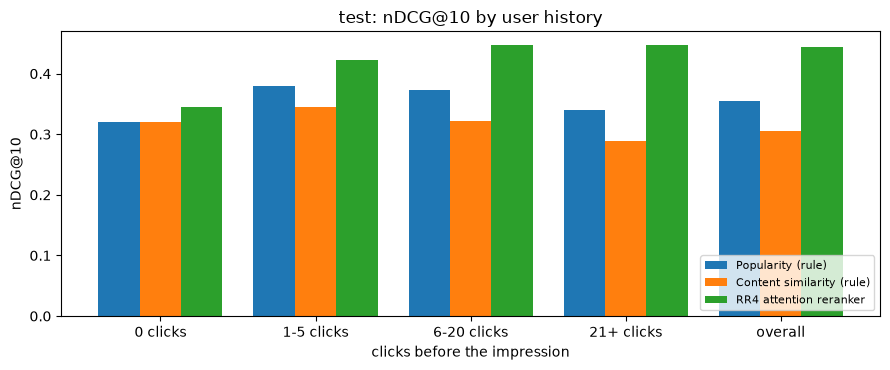

In [30]:
cohort_rows = [
    evaluator.evaluate(score_path(model_name), model_name=model_name,
                       impression_cohorts=target_cohorts, k_values=K_VALUES)
    for model_name in MODEL_NAMES
]
by_history = compare_results(cohort_rows, baseline_model=POPULARITY_MODEL)

print(f"{TARGET_SPLIT.upper()}: nDCG@10 by user history")
display(
    by_history.with_columns(pl.col("model").replace_strict(MODEL_LABELS))
    .pivot(on="model", index=["cohort", "impressions"], values="ndcg_at_10")
    .select("cohort", "impressions", *[MODEL_LABELS[name] for name in MODEL_NAMES])
    .sort(pl.col("cohort").replace_strict({c: i for i, c in enumerate(COHORT_ORDER)}))
)

groups = COHORT_ORDER + ["overall"]
width = 0.8 / len(MODEL_NAMES)
fig, ax = plt.subplots(figsize=(9, 3.8))
for index, model_name in enumerate(MODEL_NAMES):
    values = [
        by_history.filter((pl.col("model") == model_name) & (pl.col("cohort") == c))["ndcg_at_10"][0]
        for c in COHORT_ORDER
    ] + [overall.filter(pl.col("model") == model_name)["ndcg_at_10"][0]]
    ax.bar(np.arange(len(groups)) + (index - (len(MODEL_NAMES) - 1) / 2) * width, values, width,
           label=MODEL_LABELS[model_name])
ax.set_xticks(np.arange(len(groups)), groups)
ax.set(title=f"{TARGET_SPLIT}: nDCG@10 by user history", xlabel="clicks before the impression", ylabel="nDCG@10")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

# 6. Example Slate

One target-split impression, ranked by each model side by side. The click label is shown only to
read the example; no model sees it.

In [31]:
EXAMPLE_TOP_N = 10
example_uid = (
    target_slates.filter(pl.col("slate_size").is_between(15, 40) & (pl.col("clicks") == 1))
    .join(target_cohorts.filter(pl.col("history_length") >= 6), on="impression_uid")
    .sort("impression_uid")["impression_uid"][0]
)
slate = target_labels.filter(pl.col("impression_uid") == example_uid).select("news_code", "clicked").collect()
for model_name in MODEL_NAMES:
    ranks = (
        pl.scan_parquet(score_path(model_name))
        .filter(pl.col("impression_uid") == example_uid)
        .collect()
        .sort(["score", "news_code"], descending=[True, False])
        .with_row_index("rank", offset=1)
        .select("news_code", pl.col("rank").alias(MODEL_LABELS[model_name]))
    )
    slate = slate.join(ranks, on="news_code")

example_history = target_cohorts.filter(pl.col("impression_uid") == example_uid)["history_length"][0]
print(f"Impression {example_uid}: {slate.height} shown articles, user history {example_history} clicks")
display(slate.sort(MODEL_LABELS[RR4_MODEL]).head(EXAMPLE_TOP_N))
print("Rank of the clicked article under each model:")
display(slate.filter(pl.col("clicked") == 1))

Impression 20000003: 36 shown articles, user history 18 clicks


news_code,clicked,Popularity (rule),Content similarity (rule),RR4 attention reranker
i64,i8,u32,u32,u32
59685,0,3,6,1
23814,1,7,14,2
35389,0,4,12,3
36226,0,20,29,4
11817,0,23,1,5
16844,0,14,22,6
40109,0,10,31,7
23446,0,1,25,8
47098,0,9,32,9


Rank of the clicked article under each model:


news_code,clicked,Popularity (rule),Content similarity (rule),RR4 attention reranker
i64,i8,u32,u32,u32
23814,1,7,14,2


# 7. Save Outputs

- `RESULTS/rr_only_logged_slates_<split>.csv`: one row per model
- `RESULTS/rr_only_logged_slates_<split>_by_history.csv`: one row per model and history cohort
- `RESULTS/rr_only_logged_slates_<split>.json`: inputs, RR4 checkpoint and training settings, headline metrics

The files use an `rr_only_` prefix so `results.ipynb`, which collects the end-to-end `pipeline_*.csv`
files, does not mix logged-slate results into the pipeline comparison.

In [32]:
results_path = RESULTS / f"rr_only_logged_slates_{TARGET_SPLIT}.csv"
by_history_path = RESULTS / f"rr_only_logged_slates_{TARGET_SPLIT}_by_history.csv"
metadata_path = RESULTS / f"rr_only_logged_slates_{TARGET_SPLIT}.json"

overall.write_csv(results_path)
by_history.write_csv(by_history_path)
metadata_path.write_text(
    json.dumps(
        {
            "pipeline": "logged MIND slates + rule baselines and RR4 attention reranker",
            "split": TARGET_SPLIT,
            "k": list(K_VALUES),
            "impressions": int(target_slates.height),
            "seed": SEED,
            "models": MODEL_LABELS,
            "rr4_checkpoint": str(RR4_CHECKPOINT_PATH),
            "rr4_preprocessor": str(PREPROCESSOR_PATH),
            "rr4_reused": bool(RR4_LOADED),
            "rr4_best_epoch": int(model.best_epoch),
            "rr4_holdout_ndcg": float(model.best_holdout_ndcg),
            "architecture": CONFIG,
            "training": TRAINING_SETTINGS,
            "history_cohorts": COHORT_ORDER,
            "metrics": {
                row["model"]: {name: row[name] for name in ("mrr", *[f"ndcg_at_{k}" for k in K_VALUES])}
                for row in overall.iter_rows(named=True)
            },
        },
        indent=2,
    )
)
for path in (results_path, by_history_path, metadata_path):
    print("Saved:", path)

Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_logged_slates_test.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_logged_slates_test_by_history.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_logged_slates_test.json


# 8. Notes and Limitations

- **Logged slates only.** Each model reorders the articles MIND actually showed, so every
  candidate has a label and non-clicks are real negatives. This isolates ranking quality but is
  easier than the deployed task, where the reranker also faces generated candidates that were
  never shown (see `2_CG_RR_E2E`).
- **Selection happened upstream.** The content rule, and RR4's architecture and loss, were chosen
  on validation in `5_02_Reranking`. This notebook retrains the chosen RR4 configuration on the
  training split only; validation and test are never used for training or early stopping.
- **The checkpoint is reused** when `reranker/model.pt` matches the current feature schema,
  architecture and training settings. Set `REUSE_SAVED_MODELS = False` in the Configure cell to retrain.
- **Popularity is a strong baseline on logged slates.** The logging policy already favoured popular
  articles, so the shown slates suit a popularity ranking.
- **Observed CTR lift** is relative to the popularity baseline on the same logged slates. It is an
  offline proxy, not an estimate of online CTR.
- **Cohorts** use the user's click history strictly before each impression, the same causal history
  the models see.